In [1]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import numpy as np

from scipy.special import softmax

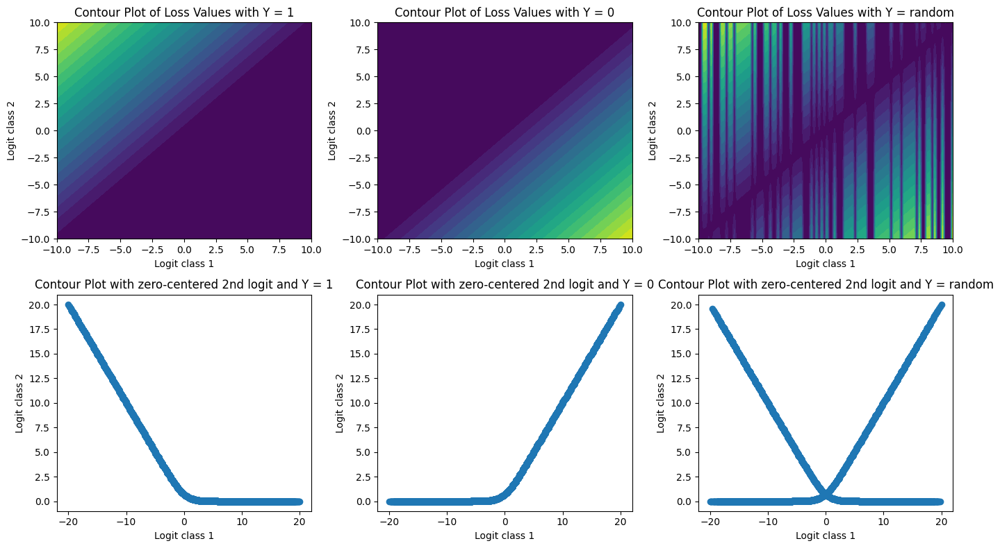

In [59]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define logits range
z_range = np.linspace(-10, 10, 100)

y1 = np.ones((100,))
y2 = np.zeros((100,))
y3 = np.random.randint(0, 2, (100,))

Z1, Z2 = np.meshgrid(z_range, z_range)
Z1_changed = Z1 - Z2
Z2_changed = Z2 - Z2

# Compute softmax probabilities
P1 = np.exp(Z1) / (np.exp(Z1) + np.exp(Z2))
P2 = np.exp(Z2) / (np.exp(Z1) + np.exp(Z2))

P1_changed = np.exp(Z1_changed) / (np.exp(Z1_changed) + np.exp(Z2_changed))
P2_changed = np.exp(Z2_changed) / (np.exp(Z1_changed) + np.exp(Z2_changed))

# Compute cross-entropy loss for both cases
loss1 = -(y1*np.log(P1) + (1-y1)*np.log(P2))
loss2 = -(y2*np.log(P1) + (1-y2)*np.log(P2))
loss3 = -(y3*np.log(P1) + (1-y3)*np.log(P2))

loss1_changed = -(y1*np.log(P1_changed) + (1-y1)*np.log(P2_changed))
loss2_changed = -(y2*np.log(P1_changed) + (1-y2)*np.log(P2_changed))
loss3_changed = -(y3*np.log(P1_changed) + (1-y3)*np.log(P2_changed))

fig, ax = plt.subplots(2, 3, figsize=(14, 8))

# Create contour plot
ax[0][0].contourf(Z1, Z2, loss1, levels=20, cmap='viridis')
ax[0][1].contourf(Z1, Z2, loss2, levels=20, cmap='viridis')
ax[0][2].contourf(Z1, Z2, loss3, levels=20, cmap='viridis')

ax[1][0].scatter(Z1_changed, loss1_changed)
ax[1][1].scatter(Z1_changed, loss2_changed)
ax[1][2].scatter(Z1_changed, loss3_changed)

# Add labels and title
ax[0][0].set_xlabel('Logit class 1');ax[0][1].set_xlabel('Logit class 1');ax[0][2].set_xlabel('Logit class 1')
ax[0][0].set_ylabel('Logit class 2');ax[0][1].set_ylabel('Logit class 2');ax[0][2].set_ylabel('Logit class 2')

ax[1][0].set_xlabel('Logit class 1');ax[1][1].set_xlabel('Logit class 1');ax[1][2].set_xlabel('Logit class 1')
ax[1][0].set_ylabel('Logit class 2');ax[1][1].set_ylabel('Logit class 2');ax[1][2].set_ylabel('Logit class 2')

ax[0][0].set_title('Contour Plot of Loss Values with Y = 1')
ax[0][1].set_title('Contour Plot of Loss Values with Y = 0')
ax[0][2].set_title('Contour Plot of Loss Values with Y = random')

ax[1][0].set_title('Contour Plot with zero-centered 2nd logit and Y = 1')
ax[1][1].set_title('Contour Plot with zero-centered 2nd logit and Y = 0')
ax[1][2].set_title('Contour Plot with zero-centered 2nd logit and Y = random')

# Display the plot
plt.tight_layout()
plt.show()

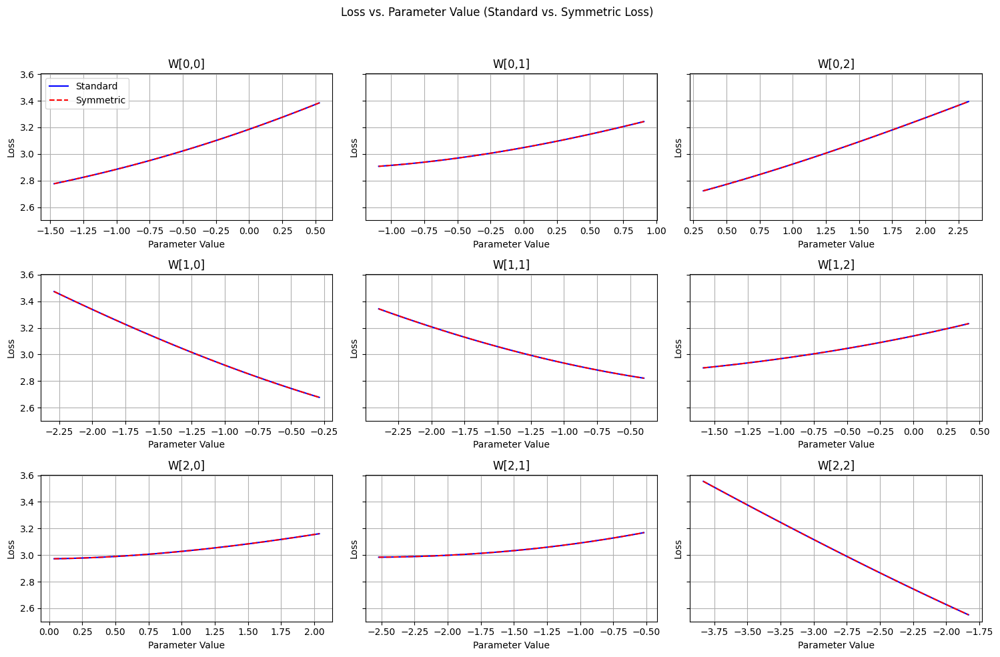

In [60]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import softmax

# Set random seed for reproducibility
np.random.seed(42)

# --- 1. Generate Synthetic Data ---
N = 1000              # number of samples
D = 3                 # number of features
K = 3                 # number of classes

# Generate random features and true labels
X = np.random.randn(N, D)
true_W = np.random.randn(K, D)
# Compute scores and choose class with max score
scores = X.dot(true_W.T)
y = np.argmax(scores, axis=1)

# Convert y to one-hot for loss computation
def one_hot(labels, num_classes):
    onehot = np.zeros((labels.size, num_classes))
    onehot[np.arange(labels.size), labels] = 1
    return onehot

y_onehot = one_hot(y, K)

# --- 2. Define Loss Functions ---

def loss_standard(W, X, y_onehot):
    """
    Computes the categorical cross-entropy loss for standard softmax.
    W: weight matrix of shape (K, D)
    X: data of shape (N, D)
    y_onehot: one-hot encoded true labels of shape (N, K)
    """
    logits = X.dot(W.T)  # shape: (N, K)
    probs = softmax(logits, axis=1)
    # Compute cross-entropy loss per sample
    loss = -np.sum(y_onehot * np.log(probs + 1e-12), axis=1)
    return np.mean(loss)

def loss_symmetric(W, X, y_onehot):
    """
    Computes the categorical cross-entropy loss after applying a symmetric transform.
    The symmetric transform subtracts the mean of the logits per sample.
    This removes the redundancy due to adding a constant.
    """
    logits = X.dot(W.T)
    # Subtract the mean across classes for each sample
    logits_sym = logits - np.mean(logits, axis=1, keepdims=True)
    probs = softmax(logits_sym, axis=1)
    loss = -np.sum(y_onehot * np.log(probs + 1e-12), axis=1)
    return np.mean(loss)

# --- 3. Baseline Weight Matrix ---
# Initialize a baseline weight matrix for both models
W_baseline = np.random.randn(K, D)

# --- 4. Visualization per Parameter ---

# We will create a grid of subplots corresponding to each parameter in W (K x D).
fig, axes = plt.subplots(K, D, figsize=(15, 10), sharey=True)
fig.suptitle("Loss vs. Parameter Value (Standard vs. Symmetric Loss)")

# Define a range for variation (for example, around the baseline value)
delta = 1.0
num_points = 100
param_range = np.linspace(-delta, delta, num_points)

# For each parameter, vary its value and compute loss curves for both losses.
for i in range(K):
    for j in range(D):
        # Copy the baseline weights to modify one parameter
        losses_std = []
        losses_sym = []
        for delta_val in param_range:
            W_test = W_baseline.copy()
            # Vary the (i,j)-th parameter: add delta_val offset to the baseline
            W_test[i, j] = W_baseline[i, j] + delta_val
            # Compute loss using both formulations
            ls = loss_standard(W_test, X, y_onehot)
            lsym = loss_symmetric(W_test, X, y_onehot)
            losses_std.append(ls)
            losses_sym.append(lsym)
        
        ax = axes[i, j]
        ax.plot(param_range + W_baseline[i, j], losses_std, label='Standard', color='blue')
        ax.plot(param_range + W_baseline[i, j], losses_sym, label='Symmetric', color='red', linestyle='--')
        ax.set_title(f"W[{i},{j}]")
        ax.set_xlabel("Parameter Value")
        ax.set_ylabel("Loss")
        ax.grid(True)
        # Only add legend to one subplot to avoid clutter
        if i == 0 and j == 0:
            ax.legend()

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


# Binary Cross-entropy
$\mathcal{L}(y_i, \hat{y}_i) = -(y_iln(\hat{y}_i) + (1-y_i)ln(1-\hat{y}_i))$

In [2]:
np.random.seed(42)

def bce(y, yhat):
    min_val = 1e-15
    return -(y*np.log(np.clip(yhat, min_val, 1-min_val)) + (1-y) * np.log(np.clip(1-yhat, min_val, 1-min_val)))

# select binary label: 0 or 1
label = np.random.randint(0, 2)

# select probability values: float between 0 and 1
yhat_values = np.random.rand(100)

# find corresponding bce loss values
loss_values = bce(label, yhat_values)

# Get the indices that would sort yhat_values
sorted_indices = np.argsort(yhat_values)

# Sort both arrays yhat_values, loss_values using the indices
yhat_values = yhat_values[sorted_indices]
loss_values = loss_values[sorted_indices]

# Create an interactive 3D surface plot
fig = go.Figure(data=[go.Scatter(x=yhat_values, y=loss_values, mode='lines', name='BCE Loss')])
fig.update_layout(title=f'Plot of BCE with y = {label}', 
                  xaxis_title='Y-hat',
                    yaxis_title='Loss',
    margin=dict(l=0, r=0, b=0, t=30))

# Display the plot
fig.show()



# Categorical Cross-entropy
$\mathcal{L}(y_i, \hat{y}_i) = -\sum\limits_{k=1}^K y_{ik}ln(\hat{y}_{ik})$

In [3]:
np.random.seed(3)

def cce(y, yhat):
    min_val = 1e-15

    # axis=1 or else axis=0 is default, which will give me total loss instead of sample-wise loss
    return -(y*np.log(np.clip(yhat, min_val, 1-min_val))).sum(axis=1)

# decide the no. of classes, K
K = 2

y = np.zeros(K)

label = np.random.randint(1, K+1)
y[label-1] = 1

# dirichlet distribution is s.t. each K-sized array has sum = 1,
# and each element in the range [0,1]
yhat_values = np.random.dirichlet(alpha=np.ones(K), size=100)
loss_values = cce(y, yhat_values)

# Create an interactive 3D surface plot
fig = go.Figure(data=[go.Scatter3d(
    x=yhat_values[:, 0], 
    y=yhat_values[:, 1], 
    z=loss_values,
    mode='markers',  # Use 'markers', 'lines', or 'lines+markers'
    marker=dict(
        size=5,          # Marker size
        color=loss_values,         # Color based on z values
        colorscale='Viridis',  # Color scale
        opacity=0.8      # Transparency
    )
)])
fig.update_layout(title='Interactive 3D Surface Plot of CCE (K = 2)', scene = dict(
                    xaxis_title='Class-1 probability',
                    yaxis_title='Class-2 probability',
                    zaxis_title='CCE(K = 2)'),
    width=800,  # Set the width
    height=600,  # Set the height
    margin=dict(l=0, r=0, b=0, t=30))

# Display the plot
fig.show()


In [4]:
np.random.seed(3)

def cce(y, yhat):
    min_val = 1e-15

    # axis=1 or else axis=0 is default, which will give me total loss instead of sample-wise loss
    return -(y*np.log(np.clip(yhat, min_val, 1-min_val))).sum(axis=1)

# decide the no. of classes, K
K = 3

y = np.zeros(K)

label = np.random.randint(1, K+1)
y[label-1] = 1

# dirichlet distribution is s.t. each K-sized array has sum = 1,
# and each element in the range [0,1]
yhat_values = np.random.dirichlet(alpha=np.ones(K), size=100)
loss_values = cce(y, yhat_values)

# Create an interactive 3D surface plot
fig = go.Figure(data=[go.Scatter3d(
    x=yhat_values[:, 0], 
    y=yhat_values[:, 1], 
    z=loss_values,
    mode='markers',  # Use 'markers', 'lines', or 'lines+markers'
    marker=dict(
        size=5,          # Marker size
        color=loss_values,         # Color based on z values
        colorscale='Viridis',  # Color scale
        opacity=0.8      # Transparency
    )
)])
fig.update_layout(title=f'Interactive 3D Surface Plot of CCE (K = 3), y = {label}', scene = dict(
                    xaxis_title='Class-1 probability',
                    yaxis_title='Class-2 probability',
                    zaxis_title='CCE(K = 3)'),
    width=800,  # Set the width
    height=600,  # Set the height
    margin=dict(l=0, r=0, b=0, t=30))

# Display the plot
fig.show()


CCE but assuming the logits to be predicted values without any redundancy removed

In [5]:
np.random.seed(3)

def cce(y, yhat):
    min_val = 1e-15

    # axis=1 or else axis=0 is default, which will give me total loss instead of sample-wise loss
    return -(y*np.log(np.clip(yhat, min_val, 1-min_val))).sum(axis=1)

# decide the no. of classes, K
K, n = 3, 10000

y = np.zeros(K)

label = np.random.randint(1, K+1)
y[label-1] = 1

# dirichlet distribution is s.t. each K-sized array has sum = 1,
# and each element in the range [0,1]
predicted_logits = np.random.normal(loc = 3, scale = 2, size = (n, K))
yhat_values = softmax(predicted_logits, axis=1)
loss_values = cce(y, yhat_values)

# Create an interactive 3D surface plot
go_fig = make_subplots(
    rows=1, 
    cols=2, 
    subplot_titles=(
    f'Interactive 3D Surface Plot of CCE (K = 3), y = {label}', 
    "CCE(K = 3) with loss against logits"),
    specs=[[{"type": "scene"}, {"type": "scene"}]],  # Define all subplots as 3D
)
go_fig.add_trace(
    go.Scatter3d(
        x=yhat_values[:, 0], 
        y=yhat_values[:, 1], 
        z=loss_values,
        mode='markers',  # Use 'markers', 'lines', or 'lines+markers'
        marker=dict(
            size=5,          # Marker size
            color=loss_values,         # Color based on z values
            colorscale='Viridis',  # Color scale
            opacity=0.8      # Transparency
        )
    ),
    row=1,
    col=1
)
go_fig.add_trace(
    go.Scatter3d(
        x=predicted_logits[:, 0], 
        y=predicted_logits[:, 1], 
        z=loss_values,
        mode='markers',  # Use 'markers', 'lines', or 'lines+markers'
        marker=dict(
            size=5,          # Marker size
            color=loss_values,         # Color based on z values
            colorscale='mygbm',  # Color scale
            opacity=0.8      # Transparency
        )
    ),
    row=1,
    col=2
)

go_fig.update_layout(
    scene = dict(xaxis_title="p1", yaxis_title = "p2", zaxis_title=f"CCE(K={K})"),
    scene2 = dict(xaxis_title="z1", yaxis_title = "z2", zaxis_title=f"CCE(K={K})"),
    margin=dict(l=0, r=0, b=0, t=30)
)

# Display the plot
go_fig.show()


In [ ]:
# Create a contour plot
fig = go.Figure(data=go.Contour(
        x=predicted_logits[:100, 0], 
        y=predicted_logits[:100, 1], 
        z=loss_values[:100],
        colorscale='Viridis',  # Color scale
    )
)
fig.show()

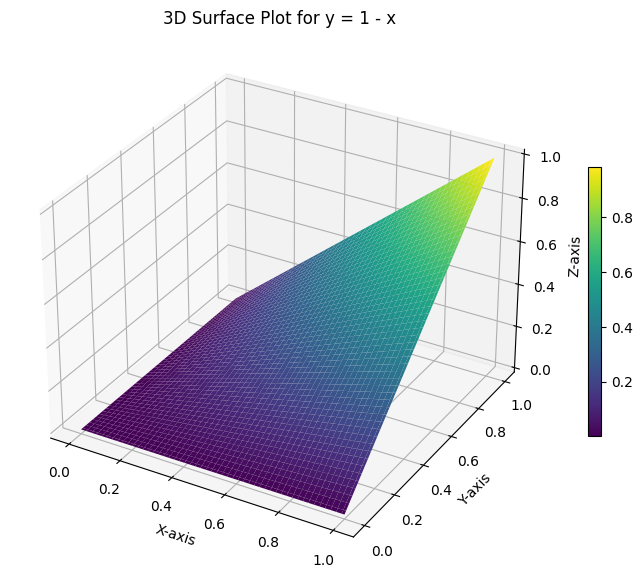

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

# Define the range for x and y
x = np.random.rand
y = 1 - x                   # y = 1 - x

# Create a meshgrid for surface plotting
X, Y = np.meshgrid(x, y)

# Define z as a function of x and y (example: z = X + Y)
Z = X * Y  # Example: z = x * y (you can choose any function)

# Plot the 3D surface
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X, Y, Z, cmap='viridis', edgecolor='none')

# Customize the plot
ax.set_xlabel('X-axis')
ax.set_ylabel('Y-axis')
ax.set_zlabel('Z-axis')
ax.set_title('3D Surface Plot for y = 1 - x')
plt.colorbar(surf, ax=ax, shrink=0.5)
plt.show()


In [3]:
import numpy as np
import plotly.graph_objects as go

# Define the range for x and y
x = np.linspace(0, 1, 100)  # x ranges from 0 to 1
y = 1 - x                   # y = 1 - x

# Create a meshgrid for surface plotting
X, Y = np.meshgrid(x, y)

# Define z as a function of x and y (example: z = X + Y)
Z = X * Y  # Example: z = x * y (you can choose any function)

# Plot the 3D surface
fig = go.Figure(data = [go.Surface(x=x, y=y, z=Z)])
fig.update_layout(title='Interactive 3D Surface Plot', scene = dict(
                    xaxis_title='X-axis',
                    yaxis_title='Y-axis',
                    zaxis_title='Z-axis'))

# Display the plot
fig.show()